In [84]:
!pip install arch

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas_datareader.data as web
import yfinance as yf

import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch import arch_model
from statsmodels.tsa.arima.model import ARIMA

In [86]:
#Date range and stock

symbol = '^NSEI'
start_date = '2000-01-01'
end_date = '2024-04-01'

#Data import

df = yf.download(symbol, start=start_date, end=end_date)

print(df.head())

[*********************100%%**********************]  1 of 1 completed

                   Open         High          Low        Close    Adj Close  \
Date                                                                          
2007-09-17  4518.450195  4549.049805  4482.850098  4494.649902  4494.649902   
2007-09-18  4494.100098  4551.799805  4481.549805  4546.200195  4546.200195   
2007-09-19  4550.250000  4739.000000  4550.250000  4732.350098  4732.350098   
2007-09-20  4734.850098  4760.850098  4721.149902  4747.549805  4747.549805   
2007-09-21  4752.950195  4855.700195  4733.700195  4837.549805  4837.549805   

            Volume  
Date                
2007-09-17       0  
2007-09-18       0  
2007-09-19       0  
2007-09-20       0  
2007-09-21       0  


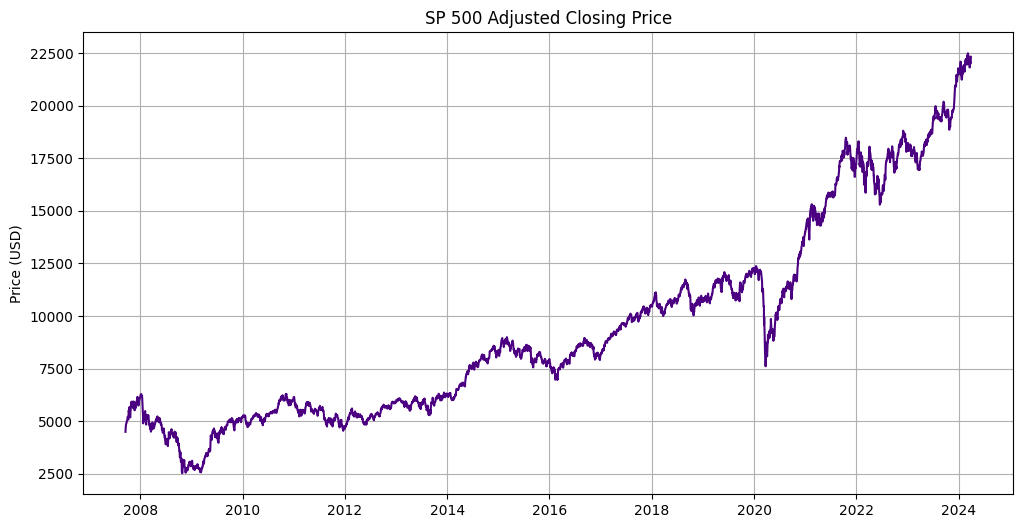

In [87]:
plt.figure(figsize = (12, 6))
plt.plot(df['Adj Close'], color='indigo')
plt.title('SP 500 Adjusted Closing Price')
plt.ylabel('Price (USD)')
plt.grid(True)
plt.show()

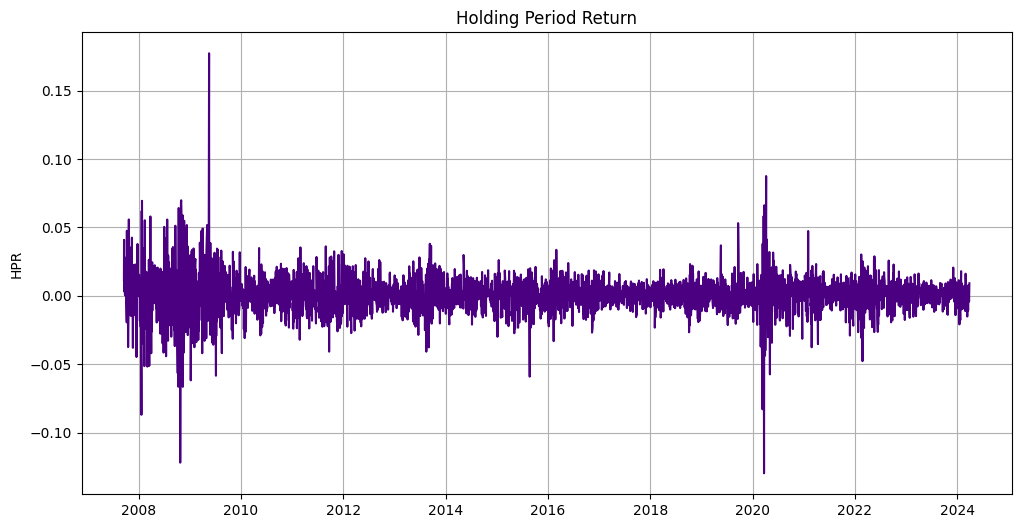

In [88]:
#Calculate Holding Period Return (HPR)

df['Return'] = df['Adj Close'].pct_change()

#Remove the first row since it will have NaN value
df = df[1:]

#Plot HPR

plt.figure(figsize = (12, 6))
plt.plot(df['Return'], color = 'indigo')
plt.title('Holding Period Return')
plt.ylabel('HPR')
plt.grid(True)
plt.show()

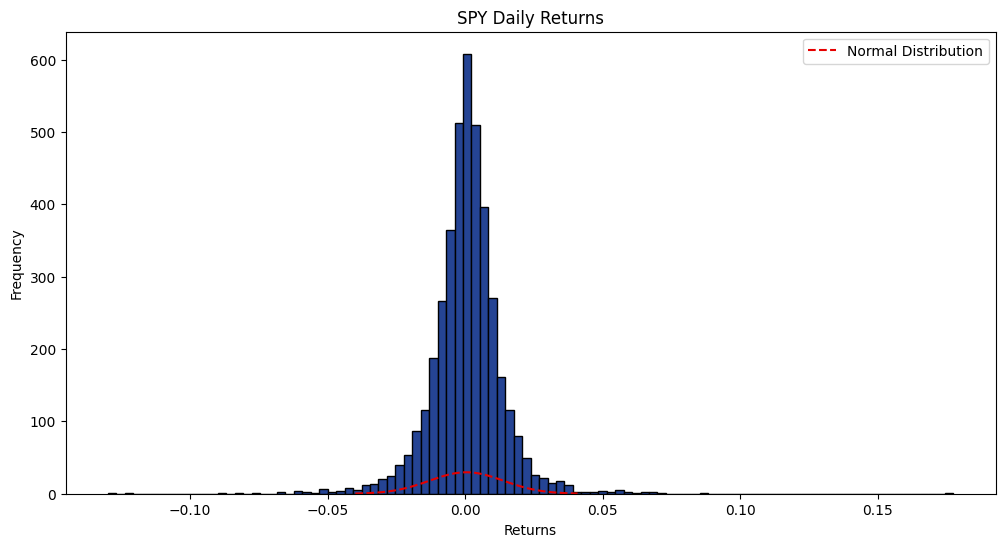

In [89]:
# Visualize the distribution of returns
plt.figure(figsize=(12, 6))
plt.hist(df['Return'], bins=100, edgecolor='black', color='#254494')
mu, sigma = np.mean(df['Return']), np.std(df['Return'])
x = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color='#e60000', linestyle='--', label='Normal Distribution')
plt.title('SPY Daily Returns')
plt.xlabel('Returns')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [90]:
import pandas as pd
import yfinance as yf  # You may need to install yfinance: pip install yfinance

# Download SPY data from Yahoo Finance
spy_data = yf.download('^NSEI', start='2000-01-01', end='2024-01-01')

# Extract daily closing prices
spy_close = spy_data['Adj Close'].pct_change()

# Calculate descriptive statistics
total_stats = pd.DataFrame({
    'Total Data (2000-2024)': [
        spy_close.mean() *100,
        spy_close.median() *100,
        spy_close.std() *100,
        spy_close.skew(),
        spy_close.kurtosis()
    ]
}, index=['Mean', 'Median', 'Standard Deviation', 'Skewness', 'Kurtosis'])

# Filter data for market distress periods
distress_2008_2009 = spy_close['2008-01-01':'2009-12-31']
distress_2020 = spy_close['2020-01-01':'2020-12-31']

# Calculate descriptive statistics for market distress periods
distress_stats = pd.DataFrame({
    'Market Distress Periods': [
        distress_2008_2009.mean() * 100,
        distress_2008_2009.median() * 100,
        distress_2008_2009.std() * 100,
        distress_2008_2009.skew(),
        distress_2008_2009.kurtosis()
    ],
    '2020': [
        distress_2020.mean() *100,
        distress_2020.median() *100,
        distress_2020.std() *100,
        distress_2020.skew(),
        distress_2020.kurtosis()
    ],

}, index=['Mean', 'Median', 'Standard Deviation', 'Skewness', 'Kurtosis'])

# Concatenate total and distress period statistics
descriptive_statistics = pd.concat([total_stats, distress_stats], axis=1)

# Print the descriptive statistics table
print(descriptive_statistics)


[*********************100%%**********************]  1 of 1 completed

                    Total Data (2000-2024)  Market Distress Periods       2020
Mean                              0.048651                -0.002301   0.075373
Median                            0.069217                 0.062083   0.229730
Standard Deviation                1.353158                 2.530916   1.973541
Skewness                          0.066340                 0.461432  -1.420738
Kurtosis                         15.308973                 5.922737  11.101813


In [91]:
# Test for normality using Shapiro-Wilk test
shapiro_test = stats.shapiro(df['Return'])
print("Shapiro-Wilk test p-value:", shapiro_test[1])

from scipy.stats import kstest

# Assuming 'spy_data' is your DataFrame containing the SPY data

# Extracting SPY data
spy_data_values = spy_data['Close'].values

# Performing the Kolmogorov-Smirnov test for normality
ks_statistic, ks_p_value = kstest(spy_data_values, 'norm')

# Printing the test results
print("Kolmogorov-Smirnov Test Results:")
print(f"KS Statistic: {ks_statistic}")
print(f"P-value: {ks_p_value}")


Shapiro-Wilk test p-value: 0.0
Kolmogorov-Smirnov Test Results:
KS Statistic: 1.0
P-value: 0.0


In [92]:
# Test for normality using Anderson-Darling test
anderson_test = stats.anderson(df['Return'], dist='norm')
print("Anderson-Darling test statistic:", anderson_test.statistic)
print("Anderson-Darling test critical values:", anderson_test.critical_values)
print("Anderson-Darling test significance levels:", anderson_test.significance_level)

Anderson-Darling test statistic: 72.8614162891381
Anderson-Darling test critical values: [0.575 0.655 0.786 0.917 1.091]
Anderson-Darling test significance levels: [15.  10.   5.   2.5  1. ]


In [93]:
# Fit Gaussian distribution
mean, std = stats.norm.fit(df['Return'])
print("Gaussian Distribution Parameters:")
print("Mean:", mean)
print("Standard Deviation:", std)

# Fit Student's t distribution
params = stats.t.fit(df['Return'])
print("\nStudent's t Distribution Parameters:")
print("Degrees of Freedom:", params[0])
print("Location:", params[1])
print("Scale:", params[2])

Gaussian Distribution Parameters:
Mean: 0.00048641524118052685
Standard Deviation: 0.01346176850670734

Student's t Distribution Parameters:
Degrees of Freedom: 2.864890425779454
Location: 0.0006850836696671395
Scale: 0.007999593796580941


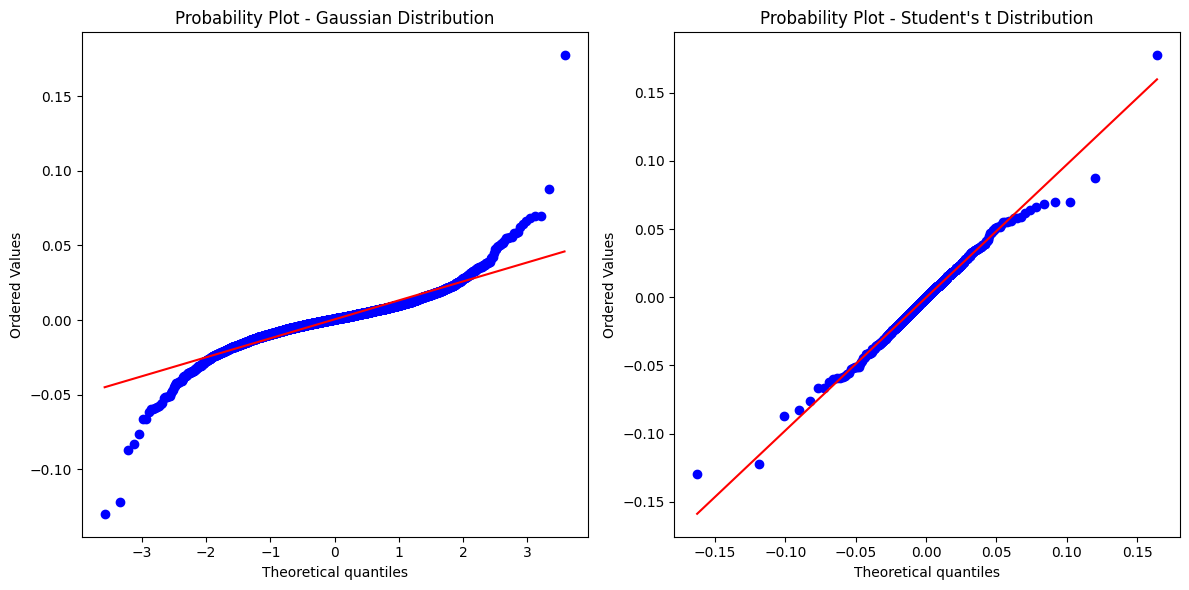

In [94]:
# Generate probability plots
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
stats.probplot(df['Return'], dist='norm', plot=plt)
plt.title('Probability Plot - Gaussian Distribution')

plt.subplot(1, 2, 2)
stats.probplot(df['Return'], dist='t', sparams=params, plot=plt)
plt.title("Probability Plot - Student's t Distribution")

plt.tight_layout()
plt.show()

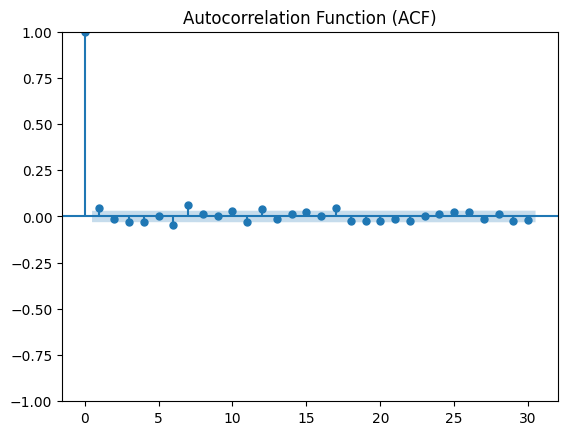

In [95]:
# Autocorrelation analysis
plot_acf(df['Return'], lags=30, alpha=0.05)
plt.title('Autocorrelation Function (ACF)')
plt.show()


In [96]:
arima_model = ARIMA(df['Return'], order=(1, 0, 0))
arima_result = arima_model.fit()
print(arima_result.summary())

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                 Return   No. Observations:                 4051
Model:                 ARIMA(1, 0, 0)   Log Likelihood               11707.102
Date:                Sat, 04 May 2024   AIC                         -23408.204
Time:                        20:41:56   BIC                         -23389.284
Sample:                             0   HQIC                        -23401.501
                               - 4051                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      2.199      0.028    5.28e-05       0.001
ar.L1          0.0439      0.008      5.244      0.000       0.028       0.060
sigma2         0.0002   1.36e-06    132.786      0.0

In [97]:
# GARCH model
garch_model = arch_model(df['Return'], vol='GARCH', p=1, q=1)
garch_result = garch_model.fit(disp='off')
print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                11409.8
Distribution:                  Normal   AIC:                          -22811.6
Method:            Maximum Likelihood   BIC:                          -22786.4
                                        No. Observations:                 4051
Date:                Sat, May 04 2024   Df Residuals:                     4050
Time:                        20:41:56   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         9.3507e-03  4.894e-03      1.911  5.605e-02 

/usr/local/lib/python3.10/dist-packages/arch/univariate/base.py:311: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0001812. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
/usr/local/lib/python3.10/dist-packages/arch/univariate/base.py:766: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


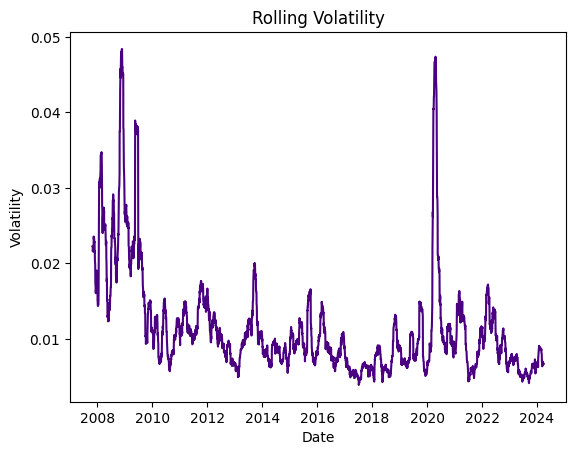

In [98]:
# Volatility clustering
rolling_volatility = df['Return'].rolling(window=30).std()
plt.plot(rolling_volatility, color='indigo')
plt.title('Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.show()

In [99]:
# Example code for event study analysis
# Define event window
event_start_date = '2008-01-01'
event_end_date = '2009-12-31'

# Filter data for the event window
event_window_data = df[(df.index >= event_start_date) & (df.index <= event_end_date)]

<ipython-input-100-e8c8a623977a>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_window_data['Event_Returns'] = event_window_data['Adj Close'].pct_change()


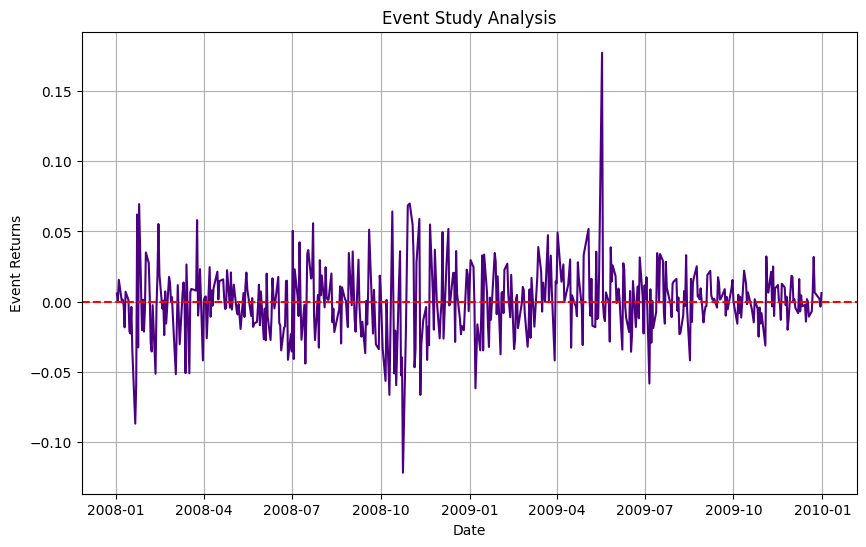

One-sample t-test:
t-statistic: -0.021723229352356054
p-value: 0.9826776863966322


In [100]:
# Compute event returns (e.g., using arithmetic returns)
event_window_data['Event_Returns'] = event_window_data['Adj Close'].pct_change()

# Perform statistical testing (e.g., t-test for mean event returns)
from scipy.stats import ttest_1samp

# Example: perform a one-sample t-test to compare event returns to the expected return (e.g., 0)
t_stat, p_value = ttest_1samp(event_window_data['Event_Returns'].dropna(), 0)

# Visualize the results (e.g., plot event returns)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(event_window_data.index, event_window_data['Event_Returns'], color='indigo')
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Event Study Analysis')
plt.xlabel('Date')
plt.ylabel('Event Returns')
plt.grid(True)
plt.show()

# Output statistical test results
print("One-sample t-test:")
print("t-statistic:", t_stat)
print("p-value:", p_value)


In [101]:
# Define event window
event_start_date = '2008-01-01'
event_end_date = '2009-12-31'

# Filter data for the event window
event_window_data = df[(df.index >= event_start_date) & (df.index <= event_end_date)]

# Calculate market returns during the event window
event_window_returns = event_window_data['Return']

# Calculate the mean and standard deviation of market returns during the event window
mean_return = event_window_returns.mean()
std_return = event_window_returns.std()

# Calculate abnormal returns
event_window_data['Abnormal_Returns'] = event_window_returns - mean_return

# Calculate cumulative abnormal returns (CAR)
event_window_data['CAR'] = event_window_data['Abnormal_Returns'].cumsum()

# Analyze trading volumes during the event window
event_window_volumes = event_window_data['Volume']

# Print summary statistics
print("Summary Statistics for Event Window:")
print("Mean Return:", mean_return)
print("Standard Deviation of Return:", std_return)

Summary Statistics for Event Window:
Mean Return: -2.301193957339379e-05
Standard Deviation of Return: 0.025309156667272983


<ipython-input-101-2ed96d6c2a28>:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_window_data['Abnormal_Returns'] = event_window_returns - mean_return
<ipython-input-101-2ed96d6c2a28>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_window_data['CAR'] = event_window_data['Abnormal_Returns'].cumsum()


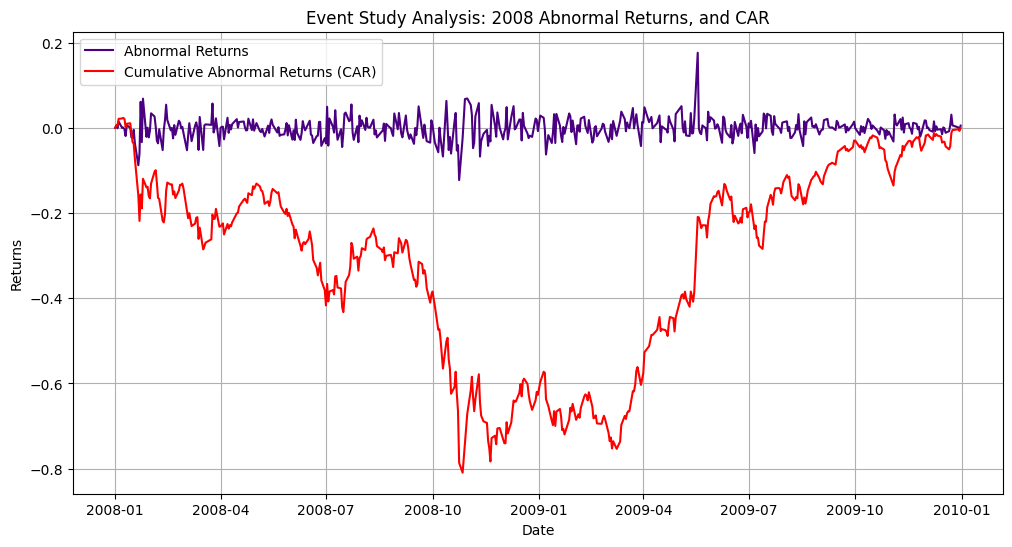

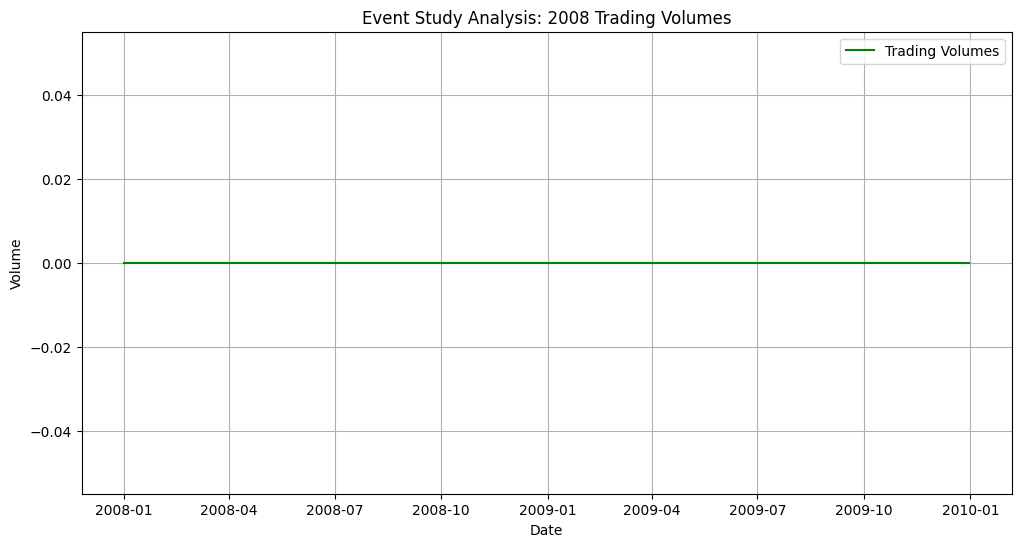

In [102]:
import matplotlib.pyplot as plt

# Plot market returns, abnormal returns, and cumulative abnormal returns (CAR)
plt.figure(figsize=(12, 6))
plt.plot(event_window_data.index, event_window_data['Abnormal_Returns'], label='Abnormal Returns', color='indigo')
plt.plot(event_window_data.index, event_window_data['CAR'], label='Cumulative Abnormal Returns (CAR)', color='red')
plt.title('Event Study Analysis: 2008 Abnormal Returns, and CAR')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.show()

# Plot trading volumes
plt.figure(figsize=(12, 6))
plt.plot(event_window_data.index, event_window_data['Volume'], label='Trading Volumes', color='green')
plt.title('Event Study Analysis: 2008 Trading Volumes')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.grid(True)
plt.show()


In [103]:
from scipy.stats import wilcoxon

# Extract the Cumulative Abnormal Returns (CAR) values
car_values = event_window_data['CAR']

# Perform the Wilcoxon signed-rank test
w_stat, p_value = wilcoxon(car_values)

# Print the test statistic and p-value
print("Wilcoxon Signed-Rank Test:")
print("Test Statistic:", w_stat)
print("p-value:", p_value)

# Interpret the results
alpha = 0.05  # significance level
if p_value < alpha:
    print("The null hypothesis (median CAR = 0) is rejected. There is significant evidence that the median CAR is not zero.")
else:
    print("The null hypothesis (median CAR = 0) cannot be rejected. There is no significant evidence that the median CAR is not zero.")


Wilcoxon Signed-Rank Test:
Test Statistic: 159.0
p-value: 6.524905440125492e-81
The null hypothesis (median CAR = 0) is rejected. There is significant evidence that the median CAR is not zero.


In [104]:
# Assuming you have a DataFrame named 'spy_data' containing SPY data from 2000-01-01 to 2024-01-01

# Filter data for the periods 2000-2010 and 2010-2024
spy_data_2000_2010 = spy_data[(spy_data.index >= '2000-01-01') & (spy_data.index < '2010-01-01')]
spy_data_2010_2024 = spy_data[(spy_data.index >= '2010-01-01') & (spy_data.index < '2024-01-01')]

# Calculate the worst loss in each period
worst_loss_2000_2010 = (spy_data_2000_2010['Adj Close'].min() - spy_data_2000_2010['Adj Close'].max()) / spy_data_2000_2010['Adj Close'].max() * 100
worst_loss_2010_2024 = (spy_data_2010_2024['Adj Close'].min() - spy_data_2010_2024['Adj Close'].max()) / spy_data_2010_2024['Adj Close'].max() * 100

print("Worst Loss in the period 2000-2010: {:.2f}%".format(worst_loss_2000_2010))
print("Worst Loss in the period 2010-2024: {:.2f}%".format(worst_loss_2010_2024))


Worst Loss in the period 2000-2010: -59.86%
Worst Loss in the period 2010-2024: -79.13%


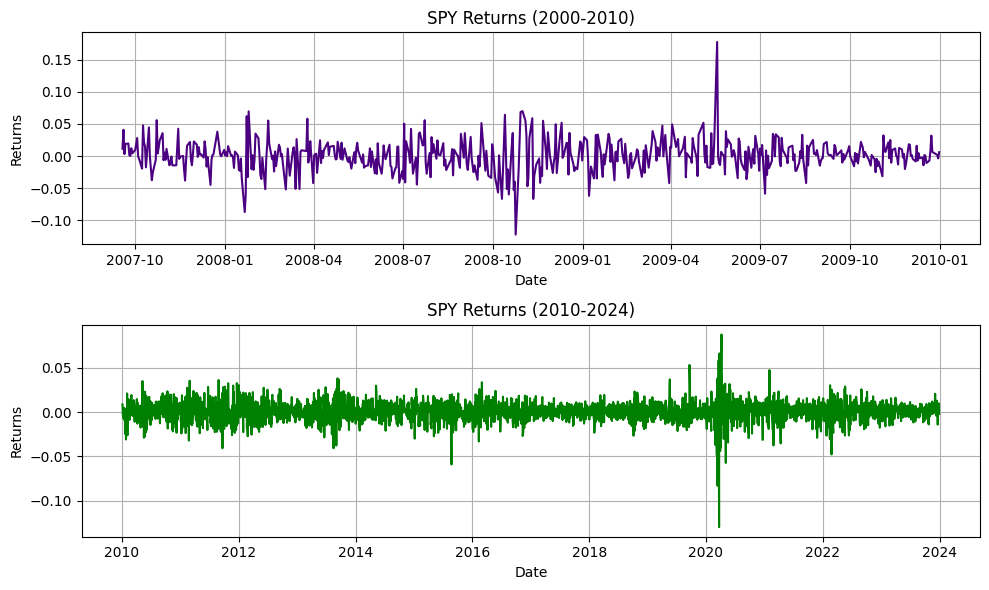

In [105]:
import matplotlib.pyplot as plt

# Calculate the returns for the periods 2000-2010 and 2010-2024
returns_2000_2010 = spy_data_2000_2010['Close'].pct_change().dropna()
returns_2010_2024 = spy_data_2010_2024['Close'].pct_change().dropna()

# Plotting
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(returns_2000_2010, color='indigo')
plt.title('SPY Returns (2000-2010)')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(returns_2010_2024, color='green')
plt.title('SPY Returns (2010-2024)')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.grid(True)

plt.tight_layout()
plt.show()


<ipython-input-106-660963138df7>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_window_data['Event_Returns'] = event_window_data['Adj Close'].pct_change()


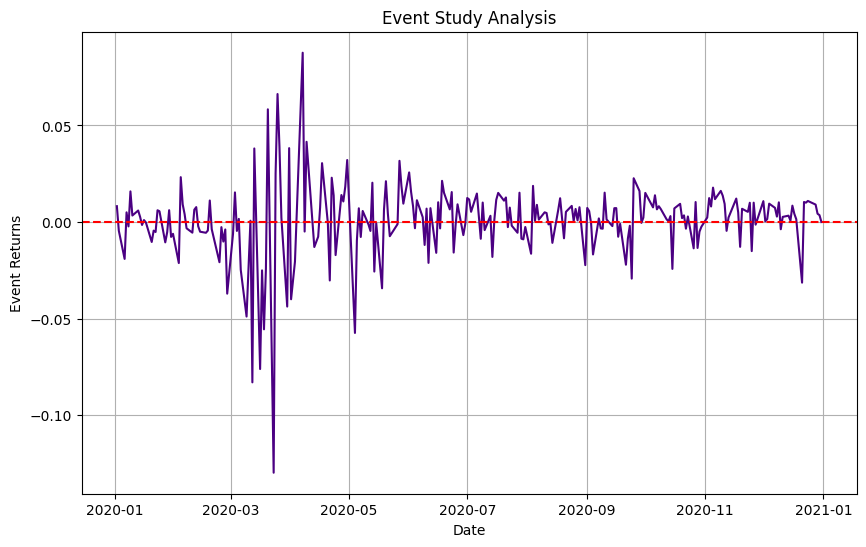

One-sample t-test:
t-statistic: 0.6001569757550226
p-value: 0.5489496217823779


In [106]:
# Define event window
event_start_date = '2020-01-01'
event_end_date = '2020-12-31'

# Filter data for the event window
event_window_data = df[(df.index >= event_start_date) & (df.index <= event_end_date)]

# Compute event returns (e.g., using arithmetic returns)
event_window_data['Event_Returns'] = event_window_data['Adj Close'].pct_change()

# Perform statistical testing (e.g., t-test for mean event returns)
from scipy.stats import ttest_1samp

# Example: perform a one-sample t-test to compare event returns to the expected return (e.g., 0)
t_stat, p_value = ttest_1samp(event_window_data['Event_Returns'].dropna(), 0)

# Visualize the results (e.g., plot event returns)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(event_window_data.index, event_window_data['Event_Returns'], color='indigo')
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Event Study Analysis')
plt.xlabel('Date')
plt.ylabel('Event Returns')
plt.grid(True)
plt.show()

# Output statistical test results
print("One-sample t-test:")
print("t-statistic:", t_stat)
print("p-value:", p_value)

In [107]:
# Define event window
event_start_date = '2020-01-01'
event_end_date = '2020-12-31'

# Filter data for the event window
event_window_data = df[(df.index >= event_start_date) & (df.index <= event_end_date)]

# Calculate market returns during the event window
event_window_returns = event_window_data['Return']

# Calculate the mean and standard deviation of market returns during the event window
mean_return = event_window_returns.mean()
std_return = event_window_returns.std()

# Calculate abnormal returns
event_window_data['Abnormal_Returns'] = event_window_returns - mean_return

# Calculate cumulative abnormal returns (CAR)
event_window_data['CAR'] = event_window_data['Abnormal_Returns'].cumsum()

# Analyze trading volumes during the event window
event_window_volumes = event_window_data['Volume']

# Print summary statistics
print("Summary Statistics for Event Window:")
print("Mean Return:", mean_return)
print("Standard Deviation of Return:", std_return)

Summary Statistics for Event Window:
Mean Return: 0.0007537259026981951
Standard Deviation of Return: 0.01973540895904821


<ipython-input-107-c6f523651b84>:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_window_data['Abnormal_Returns'] = event_window_returns - mean_return
<ipython-input-107-c6f523651b84>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_window_data['CAR'] = event_window_data['Abnormal_Returns'].cumsum()


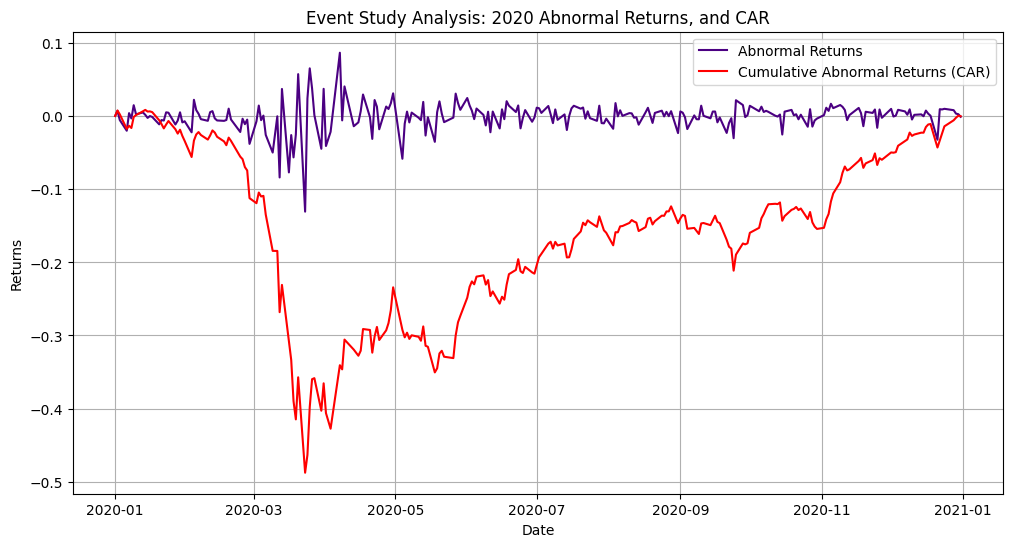

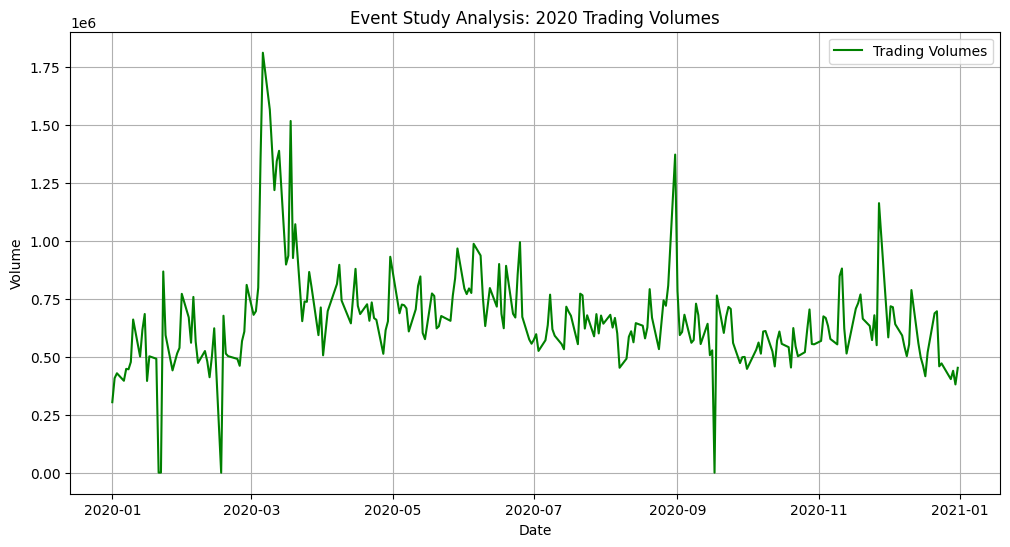

In [108]:
import matplotlib.pyplot as plt

# Plot market returns, abnormal returns, and cumulative abnormal returns (CAR)
plt.figure(figsize=(12, 6))
plt.plot(event_window_data.index, event_window_data['Abnormal_Returns'], label='Abnormal Returns', color='indigo')
plt.plot(event_window_data.index, event_window_data['CAR'], label='Cumulative Abnormal Returns (CAR)', color='red')
plt.title('Event Study Analysis: 2020 Abnormal Returns, and CAR')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.show()

# Plot trading volumes
plt.figure(figsize=(12, 6))
plt.plot(event_window_data.index, event_window_data['Volume'], label='Trading Volumes', color='green')
plt.title('Event Study Analysis: 2020 Trading Volumes')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.grid(True)
plt.show()
